# 04 – Analiza wpływu pogody na przebieg meczów

Hipotezy badawcze:
- **H1** – pojedyncze warunki atmosferyczne (temperatura, opady, wiatr) wpływają na liczbę goli, fauli i żółtych kartek.
- **H2** – połączenie niekorzystnych warunków (opady **i** silny wiatr) zmniejsza liczbę goli.

Wejście: `data/processed/final_dataset.csv`. Wykresy trafiają do `reports/figures/`, a tabele do `reports/tables/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import TTestIndPower

DATA_FILE = Path('../data/processed/final_dataset.csv')
FIGURES_DIR = Path('../reports/figures')
TABLES_DIR = Path('../reports/tables')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_style('whitegrid')


def save_figure(name):
    plt.savefig(FIGURES_DIR / f'{name}.png', dpi=120, bbox_inches='tight')

In [2]:
df = pd.read_csv(DATA_FILE, low_memory=False)
df.shape

(36271, 61)

## Przygotowanie zmiennych

In [3]:
# Zmienne opisujące policzalne zdarzenia konwertuję na liczby całkowite (Int64 obsługuje braki)
integer_cols = [
    'full_time_home_team_goals', 'full_time_away_team_goals',
    'half_time_home_team_goals', 'half_time_away_team_goals',
    'home_team_shoots', 'away_team_shoots',
    'home_team_shoots_on_target', 'away_team_shoots_on_target',
    'home_team_fouls_commited', 'away_team_fouls_commited',
    'home_team_corners', 'away_team_corners',
    'home_team_yellow_cards', 'away_team_yellow_cards',
    'home_team_red_cards', 'away_team_red_cards',
    'day_of_week', 'hour',
]
for col in integer_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce').astype('Int64')

# Sumy dla obu drużyn
df['total_goals'] = df['full_time_home_team_goals'] + df['full_time_away_team_goals']
df['total_shots'] = df['home_team_shoots'] + df['away_team_shoots']
df['total_fouls'] = df['home_team_fouls_commited'] + df['away_team_fouls_commited']
df['total_yellow_cards'] = df['home_team_yellow_cards'] + df['away_team_yellow_cards']

In [4]:
# Zmienne kategoryczne opisujące pogodę
df['is_raining'] = (df['precip_mm'] > 0).astype(int)

df['temp_category'] = pd.cut(df['temp'], bins=[-20, 5, 25, 40], labels=['Cold', 'Moderate', 'Hot'])

conditions = [
    (df['windspeed_kph'] < 12),
    (df['windspeed_kph'] >= 12) & (df['windspeed_kph'] < 25),
    (df['windspeed_kph'] >= 25),
]
choices = ['wind_light', 'wind_moderate', 'wind_strong']
df['wind_category'] = np.select(conditions, choices, default='no_data')
df['is_strong_wind'] = (df['wind_category'] == 'wind_strong').astype(int)

df[['temp', 'temp_category', 'precip_mm', 'is_raining', 'windspeed_kph', 'wind_category']].sample(5, random_state=42)

,temp,temp_category,precip_mm,is_raining,windspeed_kph,wind_category
14283,14.8,Moderate,0.0,0,14.2,wind_moderate
26766,21.0,Moderate,0.0,0,27.4,wind_strong
36104,14.1,Moderate,NaN,0,24.0,wind_moderate
34757,5.0,Cold,0.0,0,8.9,wind_light
24969,19.4,Moderate,0.0,0,14.1,wind_moderate


## Analiza eksploracyjna (EDA)

In [5]:
match_stats_cols = [
    'full_time_home_team_goals', 'full_time_away_team_goals',
    'home_team_shoots', 'away_team_shoots',
    'home_team_fouls_commited', 'away_team_fouls_commited',
    'home_team_yellow_cards', 'away_team_yellow_cards',
]
match_stats_table = df[match_stats_cols].describe().round(2)
match_stats_table.to_csv(TABLES_DIR / 'descriptive_stats_match.csv')
match_stats_table

,full_time_home_team_goals,full_time_away_team_goals,home_team_shoots,away_team_shoots,home_team_fouls_commited,away_team_fouls_commited,home_team_yellow_cards,away_team_yellow_cards
count,36271.0,36271.0,36253.0,36253.0,35496.0,35496.0,36267.0,36268.0
mean,1.53,1.18,13.74,11.09,13.66,14.06,1.87,2.16
std,1.29,1.14,5.19,4.6,4.76,4.9,1.34,1.38
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,1.0,0.0,10.0,8.0,10.0,11.0,1.0,1.0
50%,1.0,1.0,13.0,11.0,13.0,14.0,2.0,2.0
75%,2.0,2.0,17.0,14.0,17.0,17.0,3.0,3.0
max,10.0,9.0,46.0,39.0,48.0,41.0,9.0,9.0


In [6]:
weather_stats_cols = [
    'temp', 'feelslike', 'humidity', 'precip_mm',
    'windspeed_kph', 'pressure_hpa', 'cloudcover_percent',
]
weather_stats_table = df[weather_stats_cols].describe().round(4)
weather_stats_table.to_csv(TABLES_DIR / 'descriptive_stats_weather.csv')
weather_stats_table

,temp,feelslike,humidity,precip_mm,windspeed_kph,pressure_hpa,cloudcover_percent
count,36106.0000,36106.0000,36106.0000,35179.0000,36106.0000,35780.0000,35377.0000
mean,14.5277,13.8452,67.3791,0.0553,13.7514,1015.7616,56.1149
std,7.5795,8.5434,18.8791,0.4923,8.4472,9.1530,34.6660
min,-14.1000,-21.5000,6.1000,0.0000,0.0000,963.0000,0.0000
25%,9.0000,7.3000,53.9000,0.0000,7.6000,1010.8000,27.5000
50%,14.1000,14.1000,69.3000,0.0000,12.3000,1016.1000,55.0000
75%,19.9000,19.9000,82.4000,0.0000,18.4000,1021.4000,90.0000
max,40.7000,43.0000,100.0000,19.0000,70.7000,1046.8000,100.0000


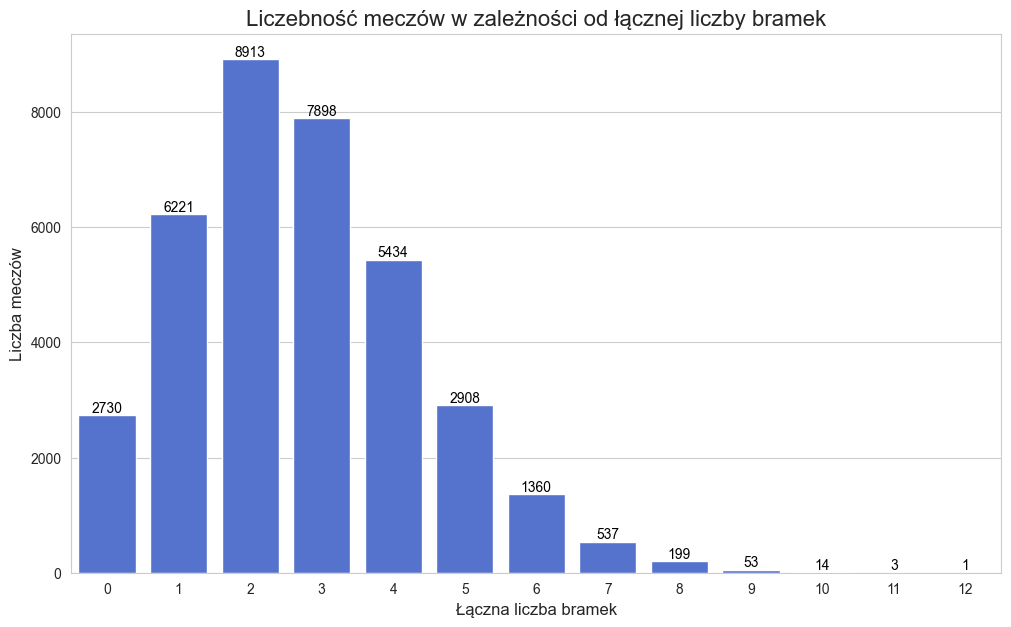

In [7]:
plt.figure(figsize=(12, 7))
ax = sns.countplot(x='total_goals', data=df, color='royalblue')

# Etykiety z dokładną liczbą meczów nad słupkami
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.title('Liczebność meczów w zależności od łącznej liczby bramek', fontsize=16)
plt.xlabel('Łączna liczba bramek', fontsize=12)
plt.ylabel('Liczba meczów', fontsize=12)
save_figure('01_total_goals_distribution')
plt.show()

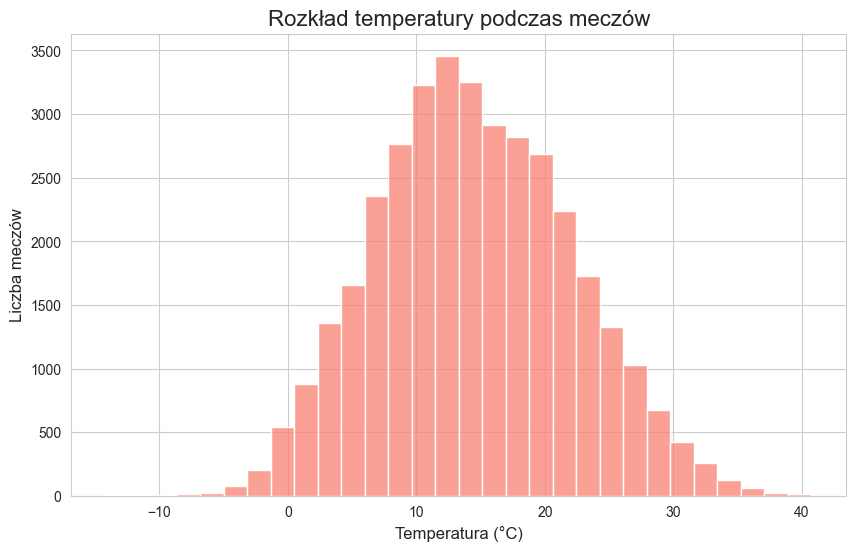

In [8]:
plt.figure(figsize=(10, 6))
sns.histplot(df['temp'].dropna(), bins=30, color='salmon')
plt.title('Rozkład temperatury podczas meczów', fontsize=16)
plt.xlabel('Temperatura (°C)', fontsize=12)
plt.ylabel('Liczba meczów', fontsize=12)
save_figure('02_temperature_distribution')
plt.show()

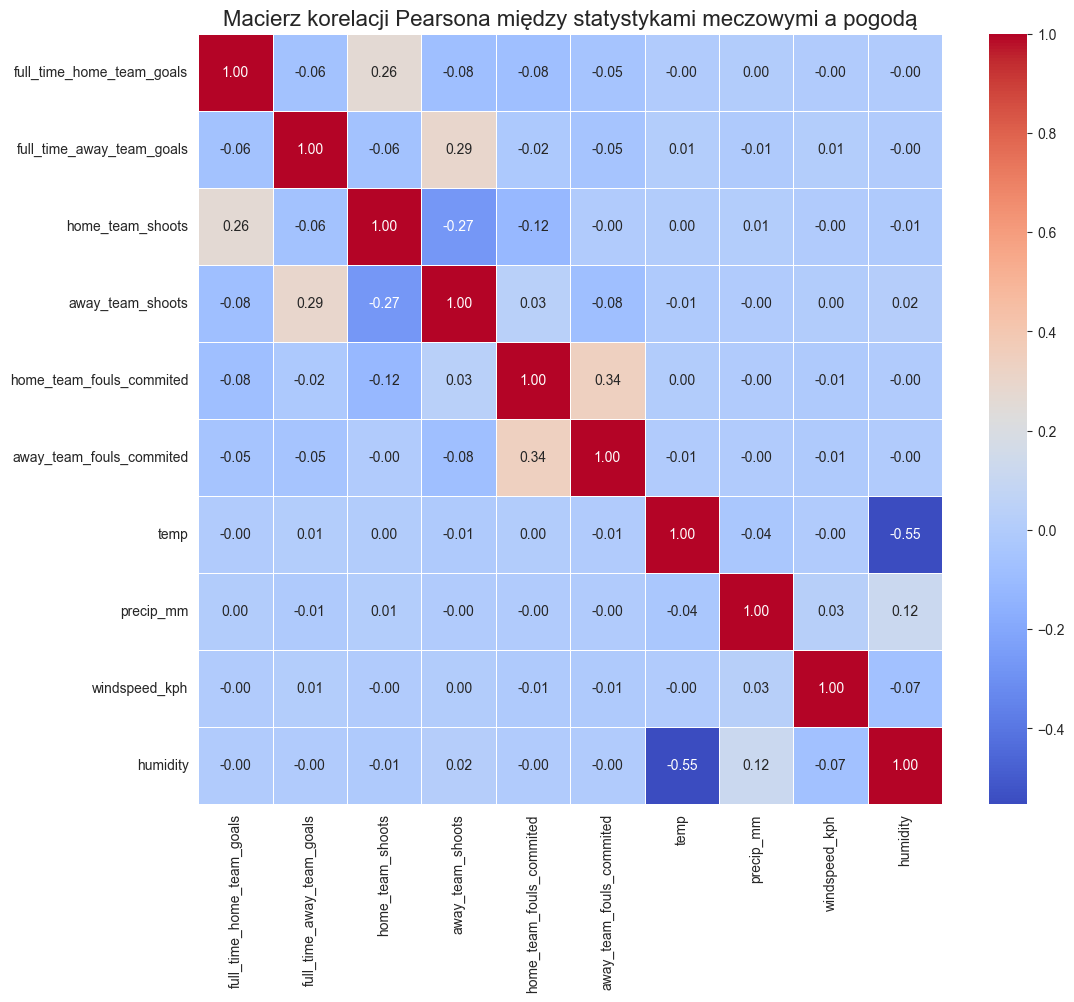

In [9]:
correlation_cols = [
    'full_time_home_team_goals', 'full_time_away_team_goals',
    'home_team_shoots', 'away_team_shoots',
    'home_team_fouls_commited', 'away_team_fouls_commited',
    'temp', 'precip_mm', 'windspeed_kph', 'humidity',
]
correlation_matrix = df[correlation_cols].corr(method='pearson')

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Macierz korelacji Pearsona między statystykami meczowymi a pogodą', fontsize=16)
save_figure('03_correlation_matrix')
plt.show()

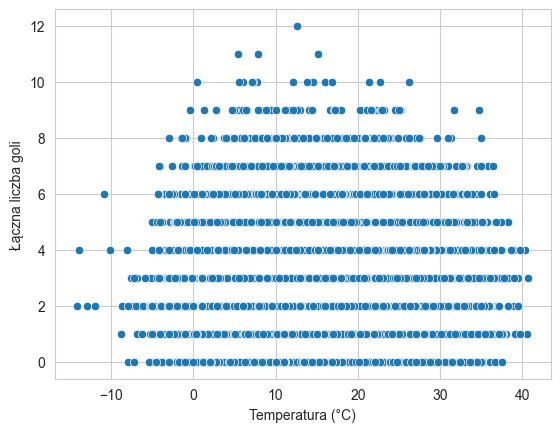

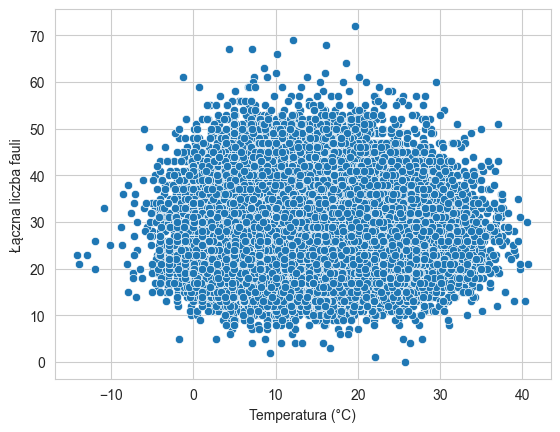

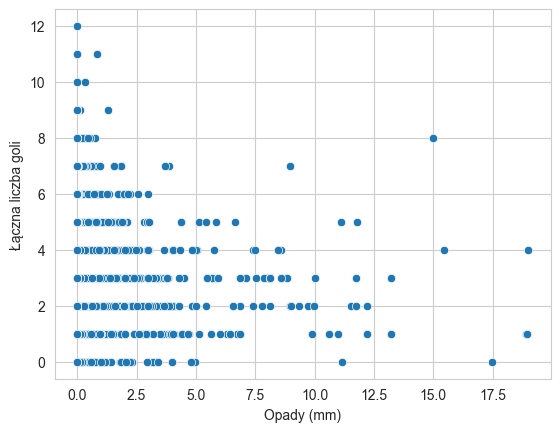

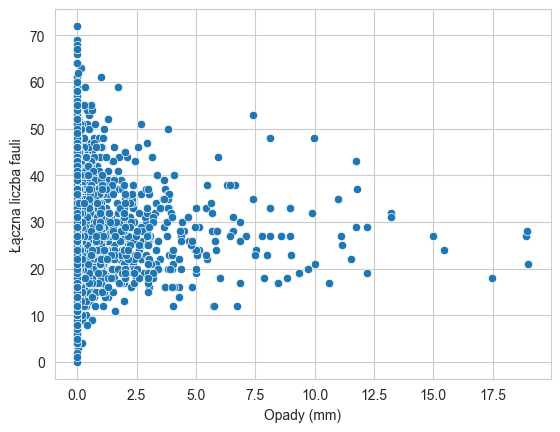

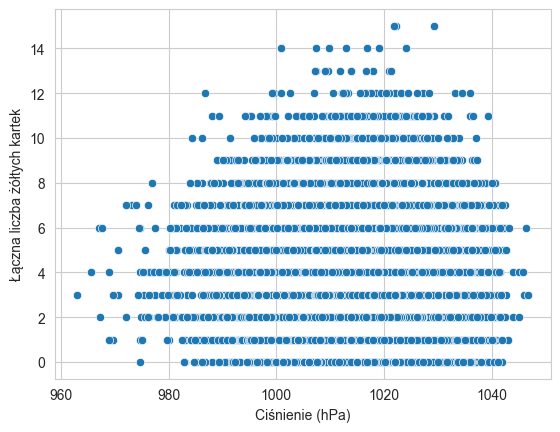

In [10]:
scatter_plots = [
    ('temp', 'total_goals', 'Temperatura (°C)', 'Łączna liczba goli', 'scatter_goals_vs_temperature'),
    ('temp', 'total_fouls', 'Temperatura (°C)', 'Łączna liczba fauli', 'scatter_fouls_vs_temperature'),
    ('precip_mm', 'total_goals', 'Opady (mm)', 'Łączna liczba goli', 'scatter_goals_vs_precipitation'),
    ('precip_mm', 'total_fouls', 'Opady (mm)', 'Łączna liczba fauli', 'scatter_fouls_vs_precipitation'),
    ('pressure_hpa', 'total_yellow_cards', 'Ciśnienie (hPa)', 'Łączna liczba żółtych kartek', 'scatter_yellow_cards_vs_pressure'),
]
for x, y, x_label, y_label, name in scatter_plots:
    plt.figure()
    sns.scatterplot(x=x, y=y, data=df)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    save_figure(name)
    plt.show()

## H1 – wpływ pojedynczych czynników pogodowych

temp_category
Cold        2.695641
Moderate    2.711494
Hot         2.685905
Name: total_goals, dtype: Float64


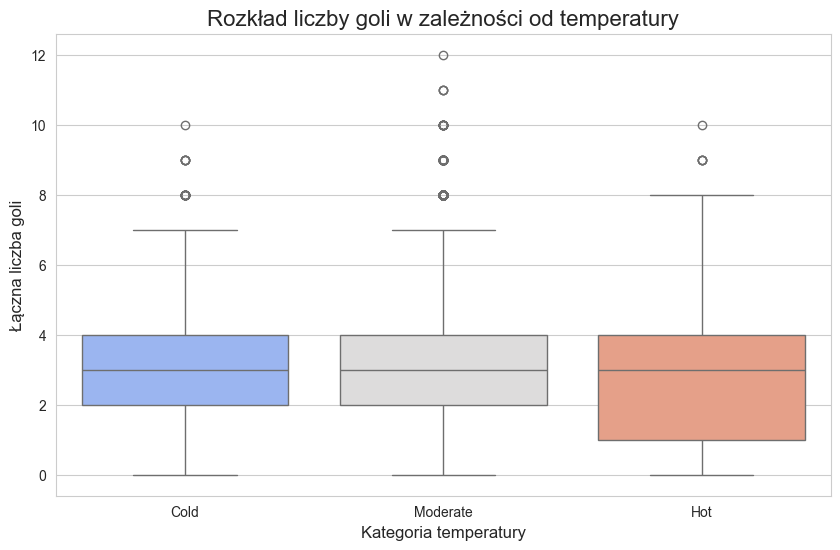

In [11]:
print(df.groupby('temp_category', observed=True)['total_goals'].mean())

plt.figure(figsize=(10, 6))
sns.boxplot(x='temp_category', y='total_goals', data=df, hue='temp_category', palette='coolwarm', legend=False)
plt.title('Rozkład liczby goli w zależności od temperatury', fontsize=16)
plt.xlabel('Kategoria temperatury', fontsize=12)
plt.ylabel('Łączna liczba goli', fontsize=12)
save_figure('04_goals_by_temperature')
plt.show()

temp_category
Cold        27.651439
Moderate    27.768521
Hot         27.581852
Name: total_fouls, dtype: Float64


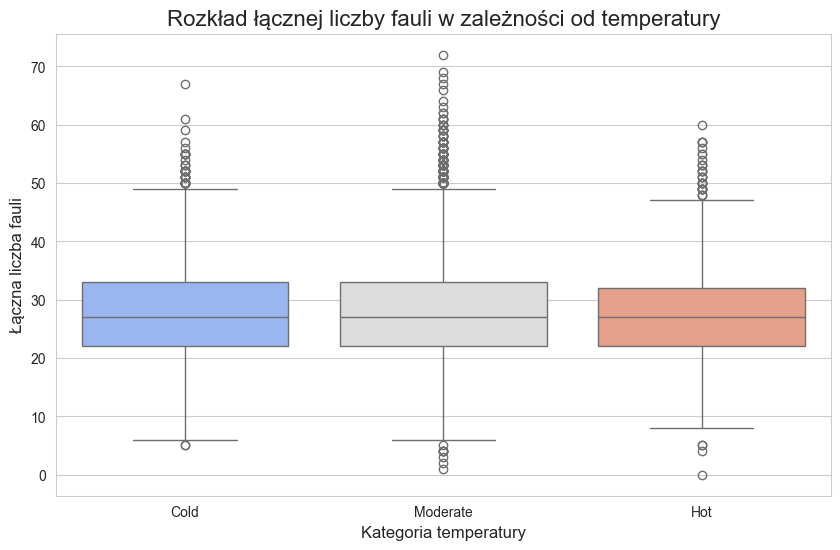

In [12]:
print(df.groupby('temp_category', observed=True)['total_fouls'].mean())

plt.figure(figsize=(10, 6))
sns.boxplot(x='temp_category', y='total_fouls', data=df, hue='temp_category', palette='coolwarm', legend=False)
plt.title('Rozkład łącznej liczby fauli w zależności od temperatury', fontsize=16)
plt.xlabel('Kategoria temperatury', fontsize=12)
plt.ylabel('Łączna liczba fauli', fontsize=12)
save_figure('05_fouls_by_temperature')
plt.show()

temp_category
Cold        3.868974
Moderate    4.046389
Hot         4.186266
Name: total_yellow_cards, dtype: Float64


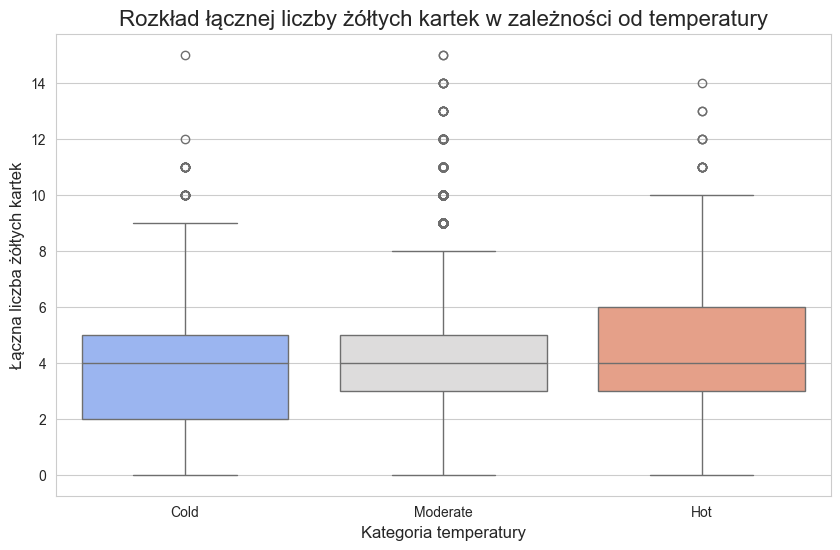

In [13]:
print(df.groupby('temp_category', observed=True)['total_yellow_cards'].mean())

plt.figure(figsize=(10, 6))
sns.boxplot(x='temp_category', y='total_yellow_cards', data=df, hue='temp_category', palette='coolwarm', legend=False)
plt.title('Rozkład łącznej liczby żółtych kartek w zależności od temperatury', fontsize=16)
plt.xlabel('Kategoria temperatury', fontsize=12)
plt.ylabel('Łączna liczba żółtych kartek', fontsize=12)
save_figure('06_yellow_cards_by_temperature')
plt.show()

is_raining
0    2.708181
1    2.694592
Name: total_goals, dtype: Float64


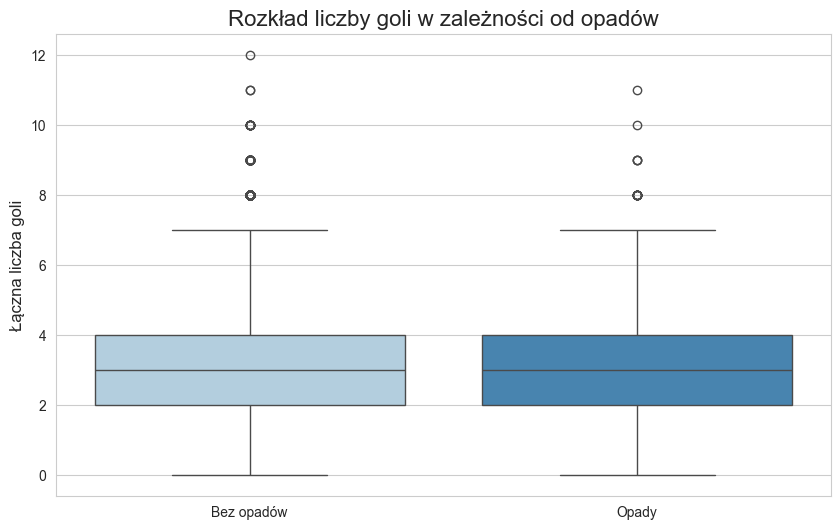

In [14]:
print(df.groupby('is_raining')['total_goals'].mean())

plt.figure(figsize=(10, 6))
sns.boxplot(x='is_raining', y='total_goals', data=df, hue='is_raining', palette='Blues', legend=False)
plt.title('Rozkład liczby goli w zależności od opadów', fontsize=16)
plt.xlabel('')
plt.ylabel('Łączna liczba goli', fontsize=12)
plt.xticks([0, 1], ['Bez opadów', 'Opady'])
save_figure('07_goals_by_rain')
plt.show()

wind_category
wind_light       2.701809
wind_moderate    2.716408
wind_strong      2.697713
Name: total_goals, dtype: Float64


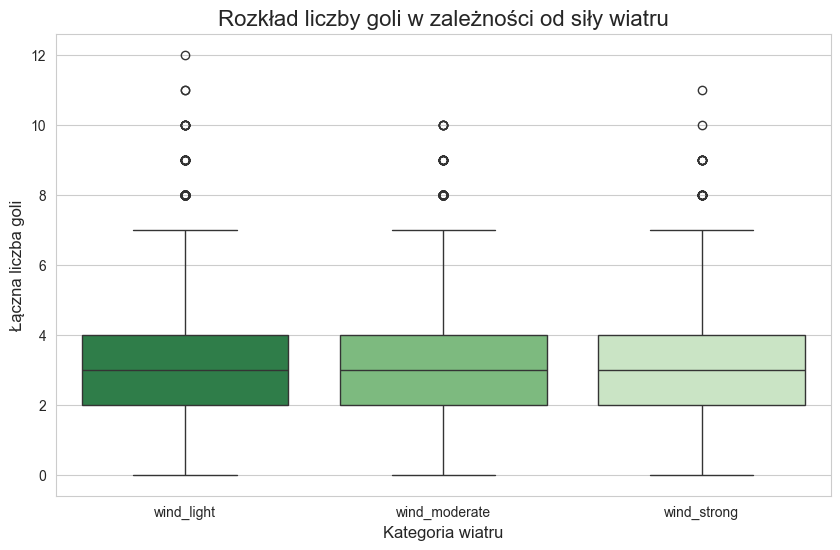

In [15]:
# Pomijam mecze bez danych o wietrze
df_for_plot = df[df['wind_category'] != 'no_data']
print(df_for_plot.groupby('wind_category')['total_goals'].mean())

plt.figure(figsize=(10, 6))
sns.boxplot(x='wind_category', y='total_goals', data=df_for_plot, hue='wind_category', palette='Greens', legend=False,
            order=['wind_light', 'wind_moderate', 'wind_strong'])
plt.title('Rozkład liczby goli w zależności od siły wiatru', fontsize=16)
plt.xlabel('Kategoria wiatru', fontsize=12)
plt.ylabel('Łączna liczba goli', fontsize=12)
save_figure('08_goals_by_wind')
plt.show()

## H2 – interakcja opadów i silnego wiatru

In [16]:
interaction_analysis = df.groupby(['is_raining', 'is_strong_wind'])['total_goals'].agg(['mean', 'std', 'count'])
interaction_analysis.round(4).to_csv(TABLES_DIR / 'rain_wind_interaction.csv')
interaction_analysis.round(4)

mean     std  count
is_raining is_strong_wind                       
0          0               2.7088   1.673  30271
           1               2.7023   1.656   3171
1          0               2.7001  1.6262   2414
           1               2.6627  1.7016    415

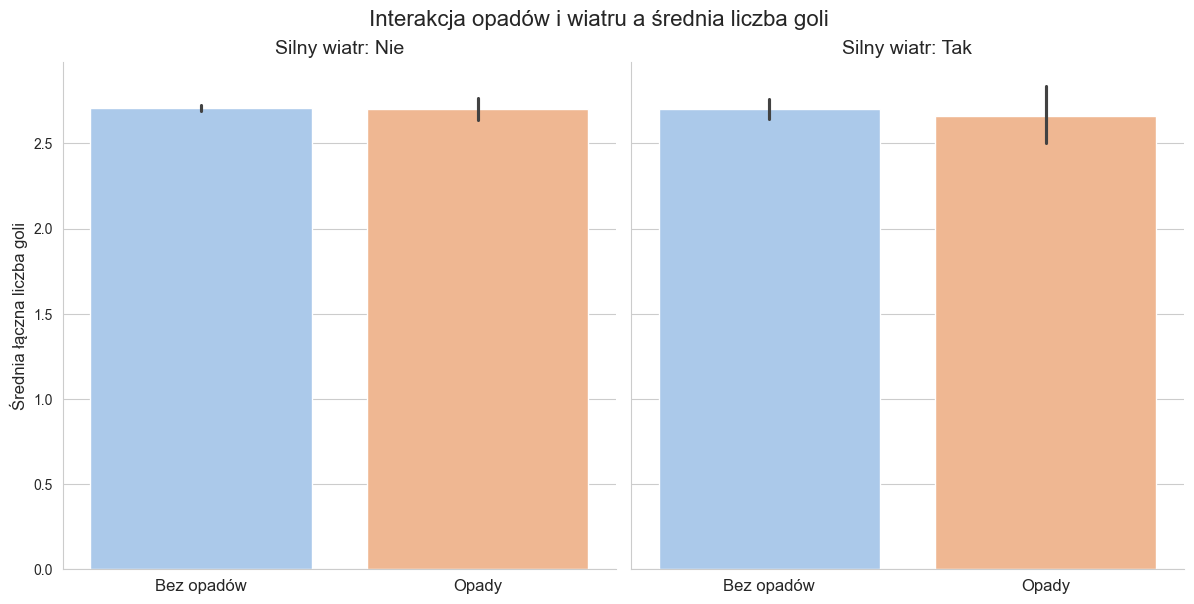

In [17]:
g = sns.catplot(x='is_raining', y='total_goals', col='is_strong_wind', data=df,
                kind='bar', hue='is_raining', palette='pastel', legend=False, height=6, aspect=1)
g.fig.suptitle('Interakcja opadów i wiatru a średnia liczba goli', y=1.03, fontsize=16)
g.set_axis_labels('', 'Średnia łączna liczba goli', fontsize=12)
g.set_xticklabels(['Bez opadów', 'Opady'], fontsize=12)
axes = g.axes.flatten()
axes[0].set_title('Silny wiatr: Nie', fontsize=14)
axes[1].set_title('Silny wiatr: Tak', fontsize=14)
save_figure('09_rain_wind_interaction')
plt.show()

### Test t Welcha: warunki ekstremalne (opady i silny wiatr) a pozostałe mecze

In [18]:
def compare_extreme_vs_normal(data):
    is_extreme = (data['is_raining'] == 1) & (data['is_strong_wind'] == 1)
    group_extreme = data.loc[is_extreme, 'total_goals'].astype(float)
    group_normal = data.loc[~is_extreme, 'total_goals'].astype(float)

    t_statistic, p_value = stats.ttest_ind(group_extreme, group_normal, equal_var=False)
    return group_extreme, group_normal, t_statistic, p_value


group_extreme, group_normal, t_statistic, p_value = compare_extreme_vs_normal(df)

print(f'Liczebność grupy ekstremalnej: {len(group_extreme)}')
print(f'Liczebność grupy normalnej: {len(group_normal)}')
print(f'Średnia dla grupy ekstremalnej: {group_extreme.mean():.4f}')
print(f'Średnia dla grupy normalnej: {group_normal.mean():.4f}\n')
print(f'Statystyka T = {t_statistic:.4f}')
print(f'P-value = {p_value:.4f}')

alpha = 0.05
if p_value < alpha:
    print(f'\np-value < {alpha}: odrzucamy hipotezę zerową – różnica jest statystycznie istotna.')
else:
    print(f'\np-value >= {alpha}: brak podstaw do odrzucenia hipotezy zerowej – różnica nie jest statystycznie istotna.')

Liczebność grupy ekstremalnej: 415
Liczebność grupy normalnej: 35856
Średnia dla grupy ekstremalnej: 2.6627
Średnia dla grupy normalnej: 2.7076

Statystyka T = -0.5356
P-value = 0.5925

p-value >= 0.05: brak podstaw do odrzucenia hipotezy zerowej – różnica nie jest statystycznie istotna.


In [19]:
def get_summary_stats(group_data, group_name):
    mean = group_data.mean()
    count = len(group_data)
    sem = stats.sem(group_data)
    ci = stats.t.interval(confidence=0.95, df=count - 1, loc=mean, scale=sem)

    return pd.Series({
        'Grupa': group_name,
        'Liczebność (n)': count,
        'Średnia (M)': mean,
        'Odch. Std. (SD)': group_data.std(),
        'Błąd Std. (SE)': sem,
        '95% CI (dolny)': ci[0],
        '95% CI (górny)': ci[1],
    })


summary_table = pd.DataFrame([
    get_summary_stats(group_normal, 'Normalna'),
    get_summary_stats(group_extreme, 'Ekstremalna'),
]).set_index('Grupa')
summary_table.round(4).to_csv(TABLES_DIR / 'extreme_vs_normal_summary.csv')
summary_table.round(4)

,Liczebność (n),Średnia (M),Odch. Std. (SD),Błąd Std. (SE),95% CI (dolny),95% CI (górny)
Grupa,,,,,,
Normalna,35856,2.7076,1.6683,0.0088,2.6904,2.7249
Ekstremalna,415,2.6627,1.7016,0.0835,2.4985,2.8268


### Wielkość efektu i analiza mocy

In [20]:
n1, n2 = len(group_normal), len(group_extreme)
std1, std2 = group_normal.std(), group_extreme.std()

# d Cohena z łączonym odchyleniem standardowym
pooled_std = np.sqrt(((n1 - 1) * std1**2 + (n2 - 1) * std2**2) / (n1 + n2 - 2))
effect_size = (group_normal.mean() - group_extreme.mean()) / pooled_std
print(f'Wielkość efektu (d Cohena): {effect_size:.4f}\n')

# Ile meczów w każdej grupie byłoby potrzebne, aby wykryć taki efekt z mocą 80% przy alpha = 0.05
required_n = TTestIndPower().solve_power(effect_size=effect_size, power=0.80, alpha=0.05,
                                         ratio=1.0, alternative='two-sided')
print(f'Wymagana liczebność każdej z grup: około {required_n:.0f} meczów.')

Wielkość efektu (d Cohena): 0.0270

Wymagana liczebność każdej z grup: około 21601 meczów.


## Test odporności: tylko mecze z poprawną datą

Dla ok. 35% meczów dane pogodowe pobrano z błędnej daty (zamieniony dzień z miesiącem, zob. notebook 01). Powtarzam test H2 tylko na meczach, w których data zapytania do API była poprawna.

In [21]:
df_correct_dates = df[~df['date_was_swapped']]
group_extreme_ok, group_normal_ok, t_ok, p_ok = compare_extreme_vs_normal(df_correct_dates)

print(f'Mecze z poprawną datą: {len(df_correct_dates)} z {len(df)}')
print(f'Grupa ekstremalna: n = {len(group_extreme_ok)}, średnia = {group_extreme_ok.mean():.4f}')
print(f'Grupa normalna: n = {len(group_normal_ok)}, średnia = {group_normal_ok.mean():.4f}')
print(f'Statystyka T = {t_ok:.4f}, p-value = {p_ok:.4f}')

Mecze z poprawną datą: 23709 z 36271
Grupa ekstremalna: n = 269, średnia = 2.6840
Grupa normalna: n = 23440, średnia = 2.7090
Statystyka T = -0.2445, p-value = 0.8070
